**Task 8: Neural Networks**

* Abel Morara

- **Objective:** Implement and evaluate perceptrons and multilayer neural networks, compare architectures and activation functions, apply early stopping, analyze loss curves, and perform regression to predict employee monthly income.

In [ ]:


from google.colab import drive
drive.mount('/content/drive')

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score, mean_squared_error

from sklearn.neural_network import MLPClassifier, MLPRegressor

# Define project directories
PROJECT_DIR = "/content/drive/MyDrive/CSC4110_G09"
DATA_DIR = os.path.join(PROJECT_DIR, "data")
OUTPUT_DIR = os.path.join(PROJECT_DIR, "outputs")
NOTEBOOK_DIR = os.path.join(PROJECT_DIR, "notebooks")

# Create folders if missing
os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs(NOTEBOOK_DIR, exist_ok=True)

# Load cleaned dataset
df = pd.read_csv(os.path.join(DATA_DIR, "clean_hr.csv"))

print("Dataset loaded successfully.")
print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())
print("\nFirst five rows:")
print(df.head())

Preparing data for Neural Network Classification

In [ ]:
# Task 8: Prepare data for neural network classification

# Separate input features and target
X = df.drop(columns=["Attrition"])
y = df["Attrition"]

# Identify and remove non-numeric columns
non_numeric_columns = X.select_dtypes(exclude=["number"]).columns.tolist()

if non_numeric_columns:
    X = X.drop(columns=non_numeric_columns)

print("Non-numeric columns removed:", non_numeric_columns)

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Standardize features
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("\nData preparation completed successfully.")
print("Training samples:", X_train_scaled.shape[0])
print("Testing samples:", X_test_scaled.shape[0])
print("Number of features:", X_train_scaled.shape[1])

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True).round(3))

Implementing a perceptron using NumPy

In [ ]:
# Task 8: Implement a simple perceptron using NumPy

class SimplePerceptron:
    def __init__(self, learning_rate=0.1, epochs=20):
        self.learning_rate = learning_rate
        self.epochs = epochs
        self.weights = None
        self.bias = 0

    def activation(self, x):
        return np.where(x >= 0, 1, 0)

    def fit(self, X, y):
        self.weights = np.zeros(X.shape[1])
        self.bias = 0

        for _ in range(self.epochs):
            for xi, target in zip(X, y):
                prediction = self.activation(np.dot(xi, self.weights) + self.bias)
                error = target - prediction

                self.weights += self.learning_rate * error * xi
                self.bias += self.learning_rate * error

    def predict(self, X):
        linear_output = np.dot(X, self.weights) + self.bias
        return self.activation(linear_output)


# AND gate dataset
X_and = np.array([
    [0, 0],
    [0, 1],
    [1, 0],
    [1, 1]
])

y_and = np.array([0, 0, 0, 1])

# Train the perceptron
and_perceptron = SimplePerceptron(learning_rate=0.1, epochs=20)
and_perceptron.fit(X_and, y_and)

# Test predictions
and_predictions = and_perceptron.predict(X_and)

print("AND Gate Perceptron")
print("-------------------")
for inputs, prediction in zip(X_and, and_predictions):
    print(f"Input: {inputs} -> Prediction: {prediction}")

Testing the perceptron on XOR

In [ ]:
# Test a single-layer perceptron on the XOR logic gate

X_xor = np.array([
    [0, 0],
    [0, 1],
    [1, 0],
    [1, 1]
])

y_xor = np.array([0, 1, 1, 0])

# Train the perceptron
xor_perceptron = SimplePerceptron(
    learning_rate=0.1,
    epochs=20
)

xor_perceptron.fit(X_xor, y_xor)

# Generate predictions
xor_predictions = xor_perceptron.predict(X_xor)

# Evaluate
xor_accuracy = accuracy_score(y_xor, xor_predictions)

print("XOR Gate - Single Layer Perceptron")
print("-----------------------------------")

for inputs, actual, predicted in zip(
    X_xor, y_xor, xor_predictions
):
    print(f"Input: {inputs} | Actual: {actual} | Predicted: {predicted}")

print(f"\nXOR Accuracy: {xor_accuracy:.2%}")
print("Perfect learning achieved:", xor_accuracy == 1.0)

Training three Neural Network classifiers (MLP)

In [ ]:
# Task 8: Compare three MLP neural network architectures

architectures = {
    "MLP_16": (16,),
    "MLP_32_16": (32, 16),
    "MLP_64_32_16": (64, 32, 16)
}

mlp_results = []
trained_mlps = {}

for model_name, layers in architectures.items():

    model = MLPClassifier(
        hidden_layer_sizes=layers,
        activation="relu",
        solver="adam",
        max_iter=500,
        random_state=42
    )

    # Train the neural network
    model.fit(X_train_scaled, y_train)

    # Predict on the test set
    y_pred = model.predict(X_test_scaled)

    # Evaluate performance
    accuracy = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)

    mlp_results.append({
        "Model": model_name,
        "Hidden Layers": layers,
        "Accuracy": accuracy,
        "F1 Score": f1
    })

    trained_mlps[model_name] = model

# Convert results to DataFrame
mlp_results = pd.DataFrame(mlp_results)

# Identify best model using F1-score
best_model_name = mlp_results.loc[
    mlp_results["F1 Score"].idxmax(), "Model"
]

best_mlp = trained_mlps[best_model_name]

print("Neural Network Classification Results")
print("=" * 55)
print(mlp_results.to_string(index=False))

print("\nBest model based on F1-score:", best_model_name)
print("Best model architecture:", best_mlp.hidden_layer_sizes)

Plot the neural network loss curve

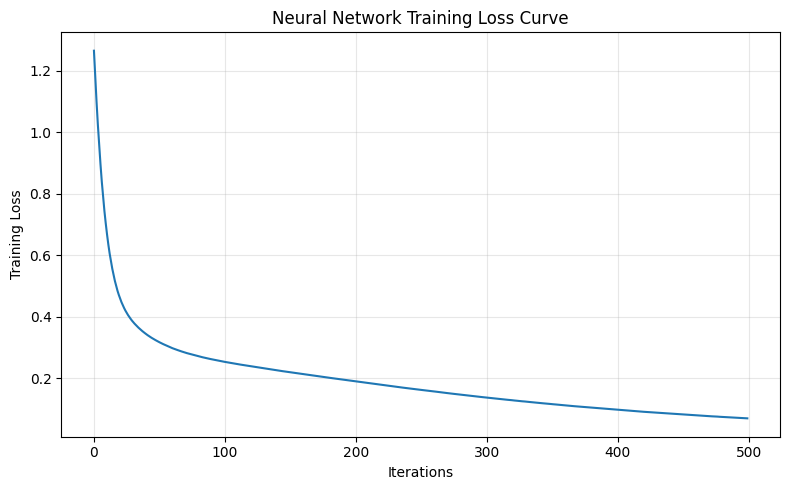

Loss curve saved to: /content/drive/MyDrive/CSC4110_G09/outputs/loss_curve.png
Training iterations: 500
Final training loss: 0.07044320846698424


In [ ]:
# Task 8: Plot training loss curve for the best MLP

plt.figure(figsize=(8, 5))

plt.plot(best_mlp.loss_curve_, marker=None)

plt.title("Neural Network Training Loss Curve")
plt.xlabel("Iterations")
plt.ylabel("Training Loss")
plt.grid(alpha=0.3)

plt.tight_layout()

# Save the plot
loss_path = os.path.join(OUTPUT_DIR, "loss_curve.png")
plt.savefig(loss_path, dpi=300, bbox_inches="tight")

plt.show()

print("Loss curve saved to:", loss_path)
print("Training iterations:", best_mlp.n_iter_)
print("Final training loss:", best_mlp.loss_)

Neural Network with Early Stopping

In [ ]:
# Train MLP using Early Stopping

early_stopping_model = MLPClassifier(
    hidden_layer_sizes=(16,),
    activation="relu",
    solver="adam",
    max_iter=500,
    early_stopping=True,
    validation_fraction=0.1,
    n_iter_no_change=10,
    random_state=42
)

early_stopping_model.fit(X_train_scaled, y_train)

early_predictions = early_stopping_model.predict(X_test_scaled)

early_accuracy = accuracy_score(y_test, early_predictions)
early_f1 = f1_score(y_test, early_predictions)

print("Early Stopping Neural Network Results")
print("---------------------------------")
print("Accuracy:", round(early_accuracy, 4))
print("F1 Score:", round(early_f1, 4))
print("Training iterations:", early_stopping_model.n_iter_)
print("Best validation score:", round(early_stopping_model.best_validation_score_, 4))

Early Stopping Neural Network Results
---------------------------------
Accuracy: 0.8537
F1 Score: 0.3944
Training iterations: 64
Best validation score: 0.9068


Comparing Activation Functions

In [ ]:
# Compare activation functions

activations = ["relu", "tanh", "logistic"]
activation_results_list = []

for activation in activations:
    model = MLPClassifier(
        hidden_layer_sizes=(16,),
        activation=activation,
        solver="adam",
        max_iter=500,
        early_stopping=True,
        random_state=42
    )

    model.fit(X_train_scaled, y_train)
    predictions = model.predict(X_test_scaled)

    activation_results_list.append({
        "Activation": activation,
        "Accuracy": accuracy_score(y_test, predictions),
        "F1 Score": f1_score(y_test, predictions),
        "Iterations": model.n_iter_
    })

activation_results = pd.DataFrame(activation_results_list)

print("Activation Function Comparison")
display(activation_results.round(4))

Activation Function Comparison


,Activation,Accuracy,F1 Score,Iterations
0,relu,0.8537,0.3944,64
1,tanh,0.8571,0.4615,60
2,logistic,0.8605,0.4384,35


Neural Network Regression – Monthly Income Prediction

In [ ]:
# Prepare data for Monthly Income prediction

X_reg = df.drop(columns=["MonthlyIncome", "Attrition"])
y_reg = df["MonthlyIncome"]

# Remove non-numeric features
non_numeric_reg = X_reg.select_dtypes(exclude=["number"]).columns.tolist()
X_reg = X_reg.drop(columns=non_numeric_reg)

# Split the dataset
X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(
    X_reg, y_reg, test_size=0.2, random_state=42
)

# Scale the input features
scaler_reg = StandardScaler()
X_train_reg_scaled = scaler_reg.fit_transform(X_train_reg)
X_test_reg_scaled = scaler_reg.transform(X_test_reg)

# Scale target values
target_scaler = StandardScaler()
y_train_reg_scaled = target_scaler.fit_transform(
    y_train_reg.values.reshape(-1, 1)
).ravel()

# Train MLP Regressor
mlp_reg = MLPRegressor(
    hidden_layer_sizes=(32, 16),
    activation="relu",
    solver="adam",
    max_iter=500,
    early_stopping=True,
    random_state=42
)

mlp_reg.fit(X_train_reg_scaled, y_train_reg_scaled)

# Predict and convert back to original income scale
reg_predictions_scaled = mlp_reg.predict(X_test_reg_scaled)
reg_predictions = target_scaler.inverse_transform(
    reg_predictions_scaled.reshape(-1, 1)
).ravel()

# Calculate RMSE
mlp_reg_rmse = np.sqrt(mean_squared_error(y_test_reg, reg_predictions))

print("Monthly Income Prediction Results")
print("--------------------------------")
print("RMSE:", round(mlp_reg_rmse, 2))
print("Training iterations:", mlp_reg.n_iter_)

Monthly Income Prediction Results
--------------------------------
RMSE: 1579.56
Training iterations: 145


In [ ]:
# Final Task 8 verification

print("TASK 8: NEURAL NETWORKS - FINAL VERIFICATION")
print("=" * 45)

print("\n1. Perceptron AND gate:", "OK")
print("2. XOR limitation experiment:", "OK")
print("3. MLP architecture comparison:", "OK" if "mlp_results" in globals() else "MISSING")
print("4. Best MLP model:", "OK" if "best_mlp" in globals() else "MISSING")
print("5. Loss curve:", "OK" if os.path.exists(os.path.join(OUTPUT_DIR, "loss_curve.png")) else "MISSING")
print("6. Early stopping:", "OK" if "early_stopping_model" in globals() else "MISSING")
print("7. Activation comparison:", "OK" if "activation_results" in globals() else "MISSING")
print("8. Monthly income regression:", "OK" if "mlp_reg_rmse" in globals() else "MISSING")

print("\nMLP Classification Results:")
display(mlp_results.round(4))

print("\nActivation Function Results:")
display(activation_results.round(4))

print("\nMonthly Income RMSE:", round(mlp_reg_rmse, 2))

print("\nTask 8 verification complete.")

TASK 8: NEURAL NETWORKS - FINAL VERIFICATION

1. Perceptron AND gate: OK
2. XOR limitation experiment: OK
3. MLP architecture comparison: OK
4. Best MLP model: OK
5. Loss curve: OK
6. Early stopping: OK
7. Activation comparison: OK
8. Monthly income regression: OK

MLP Classification Results:


,Model,Hidden Layers,Accuracy,F1 Score
0,MLP_16,"(16,)",0.8367,0.4545
1,MLP_32_16,"(32, 16)",0.8265,0.4270
2,MLP_64_32_16,"(64, 32, 16)",0.8299,0.4048



Activation Function Results:


,Activation,Accuracy,F1 Score,Iterations
0,relu,0.8537,0.3944,64
1,tanh,0.8571,0.4615,60
2,logistic,0.8605,0.4384,35



Monthly Income RMSE: 1579.56

Task 8 verification complete.




The neural network experiments demonstrated the application of perceptrons, multilayer perceptrons (MLPs), classification, regression, and activation functions using the IBM HR Analytics Employee Attrition dataset.

The single-layer perceptron successfully learned the AND logic gate but failed to perfectly classify XOR, demonstrating the limitation of linear decision boundaries. Three MLP architectures were compared, and the model with one hidden layer containing 16 neurons achieved the best F1 score of 0.4545. Early stopping was also implemented to reduce unnecessary training iterations.

The activation function experiment showed that Tanh achieved the highest F1 score of 0.4615, while Logistic obtained the highest accuracy of 86.05%. Finally, an MLP regressor was trained to predict monthly income, achieving an RMSE of 1,579.56.

Overall, the experiments demonstrated that neural network performance depends on architecture, activation functions, and training strategies. Simpler models can perform competitively with deeper models, and appropriate evaluation metrics are important when analyzing imbalanced datasets such as employee attrition.